# 03 · Aprendizaje no supervisado: tipos de día
**TráficoIA · Proyecto Final, versión 3 · Semana 2 (lunes 23 de noviembre)**

Equipo N.º _03 · Integrantes: Dávalos Chavez Francisco Javier, Moreno Rodriguez Jose Salvador, Ruiz León Michelle del Cielo, Villalva Villa Demián Alexander

**Pregunta:** si no le decimos al algoritmo qué días son laborales, de fin de semana o festivos, ¿los descubre solo a partir de la forma de su curva de tráfico? Y si lo hace, ¿qué horario de semáforo conviene a cada tipo de día?

**Método:**
1. Cada día se convierte en un punto de **24 valores** (volumen promedio en cada hora).
2. Se escala con `StandardScaler` (obligatorio antes de agrupar, para que ninguna hora pese más por tener números más grandes).
3. **K-Means**: se elige el número de grupos con el método del codo y la silueta.
4. **DBSCAN**: agrupa por densidad y marca como *ruido* los días raros. Se elige `eps` con la gráfica de distancias.
5. **PCA** solo para dibujar en 2D; los grupos se calculan con las 24 dimensiones.
6. Se interpreta cada grupo y se propone un horario de semáforo para cada tipo de día.

> **Antes de ejecutar:** haber descargado los datos (`python src/descargar_datos.py --tabular`).

In [2]:
import sys, warnings
from pathlib import Path

# Permite importar src/ aunque el cuaderno se ejecute desde notebooks/
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, no_supervisado

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
config.FIGURAS.mkdir(parents=True, exist_ok=True)

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(config.FIGURAS / f"{nombre}.png", dpi=130, bbox_inches="tight")

print("Raíz del proyecto:", RAIZ)

from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

Raíz del proyecto: C:\Users\SalvadorMoreno\Proyectos\Materia Fundamentos de IA\proyectoFinal\proyecto-ia-traficoia


## 1. De horas sueltas a perfiles diarios

Días en los datos: 1,860
Días utilizables (hasta 3 horas faltantes, interpoladas): 1,508
Matriz de perfiles: 1508 días x 24 horas


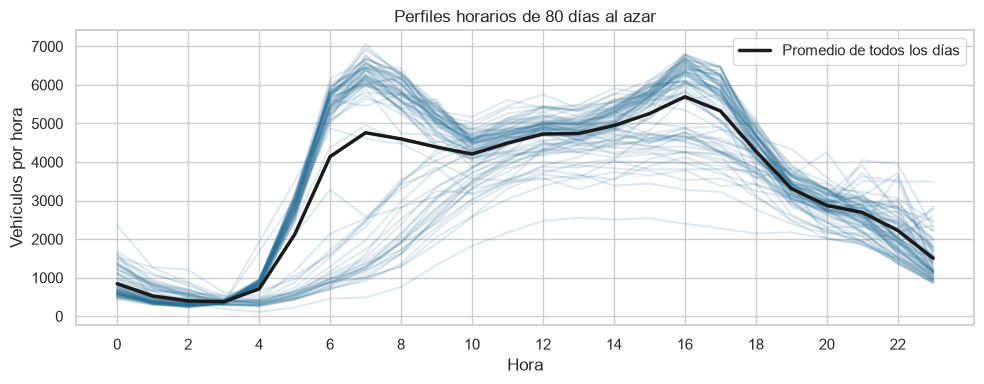

In [3]:
df = no_supervisado.cargar_datos_limpios()
perfiles = no_supervisado.matriz_perfiles(df, max_faltantes=3)
meta = no_supervisado.metadatos_dias(df)

print(f"Días en los datos: {df['fecha'].nunique():,}")
print(f"Días utilizables (hasta 3 horas faltantes, interpoladas): {len(perfiles):,}")
print(f"Matriz de perfiles: {perfiles.shape[0]} días x {perfiles.shape[1]} horas")

fig, ax = plt.subplots(figsize=(10, 4))
for _, fila in perfiles.sample(min(80, len(perfiles)), random_state=config.SEMILLA).iterrows():
    ax.plot(range(24), fila.values, alpha=0.15, color="#2a6f97")
ax.plot(range(24), perfiles.mean().values, color="k", lw=2.5, label="Promedio de todos los días")
ax.set(title="Perfiles horarios de 80 días al azar", xlabel="Hora", ylabel="Vehículos por hora", xticks=range(0, 24, 2))
ax.legend()
guardar("nosup_perfiles_diarios")
plt.show()

*Interpretación:* ¿se ven formas de día distintas a simple vista (con dos picos y con uno solo suave)? Esa estructura es lo que los algoritmos intentarán descubrir. Anota cuántos días se descartaron por tener demasiadas horas faltantes y si eso puede sesgar el resultado (por ejemplo, si faltan sobre todo días de una temporada).

## 2. Escalar las variables

In [4]:
escalador, X = no_supervisado.escalar(perfiles)
print("Forma de X:", X.shape)
print("Media por columna tras escalar (≈ 0):", np.round(X.mean(axis=0)[:5], 3), "...")
print("Desviación por columna tras escalar (≈ 1):", np.round(X.std(axis=0)[:5], 3), "...")

Forma de X: (1508, 24)
Media por columna tras escalar (≈ 0): [ 0.  0. -0.  0.  0.] ...
Desviación por columna tras escalar (≈ 1): [1. 1. 1. 1. 1.] ...


## 3. K-Means: ¿cuántos grupos?
Dos criterios, que se leen juntos:
* **Codo:** la inercia (suma de distancias al centro) siempre baja al aumentar k; se busca el punto donde la mejora se vuelve pequeña.
* **Silueta:** entre −1 y 1, mide qué tan separados están los grupos. Más alta es mejor.

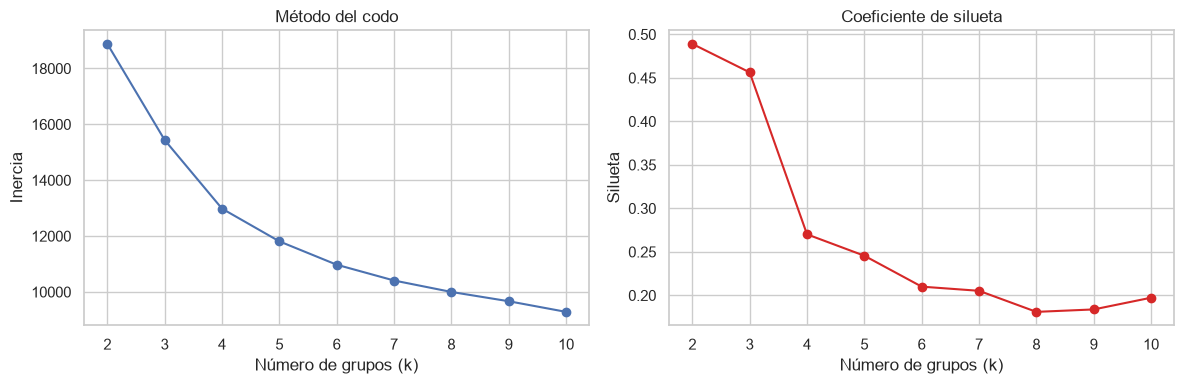

,k,inercia,silueta
0,2,18880.899,0.489
1,3,15438.524,0.456
2,4,12982.118,0.270
3,5,11811.019,0.246
4,6,10974.864,0.210
5,7,10409.705,0.205
6,8,9999.929,0.181
7,9,9667.505,0.184
8,10,9286.805,0.197


In [5]:
ev = no_supervisado.evaluar_k(X, ks=range(2, 11))
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(ev["k"], ev["inercia"], marker="o")
ejes[0].set(title="Método del codo", xlabel="Número de grupos (k)", ylabel="Inercia")
ejes[1].plot(ev["k"], ev["silueta"], marker="o", color="#d62828")
ejes[1].set(title="Coeficiente de silueta", xlabel="Número de grupos (k)", ylabel="Silueta")
for ax in ejes:
    ax.set_xticks(range(2, 11))
guardar("nosup_codo_silueta")
plt.show()
ev.round(3)

**Decisión de k (escríbela y justifícala).** El código propone el k con mayor silueta, pero **tú decides**: la silueta suele favorecer k = 2 (laboral frente a fin de semana), mientras que el codo o el sentido del problema pueden pedir 3 o más (por ejemplo, separar festivos o viernes). Cambia `K_ELEGIDO` si tu justificación apunta a otro valor.

In [6]:
K_ELEGIDO = 3

K = K_ELEGIDO or no_supervisado.k_por_silueta(ev)
print("k usado:", K, "(propuesto por silueta)" if K_ELEGIDO is None else "(elegido por el equipo)")
km = no_supervisado.kmeans_final(X, K)
print("Silueta con ese k:", round(float(ev.loc[ev['k'] == K, 'silueta'].iloc[0]), 3))

k usado: 3 (elegido por el equipo)
Silueta con ese k: 0.456


Se elige k = 3 en lugar del k = 2 sugerido únicamente por el índice de silueta (0.489), ya que para la programación de ciclos de semáforos resulta insuficiente dividir la semana en solo dos perfiles. Con k = 3 se logra diferenciar claramente el patrón bimodal de días laborales (picos marcados de entrada y salida), el patrón intermedio de sábados/viernes y el patrón de baja demanda correspondiente a domingos y días festivos.

## 4. Visualizar con PCA

Varianza explicada por PC1 y PC2: [0.572 0.207] | total: 0.779


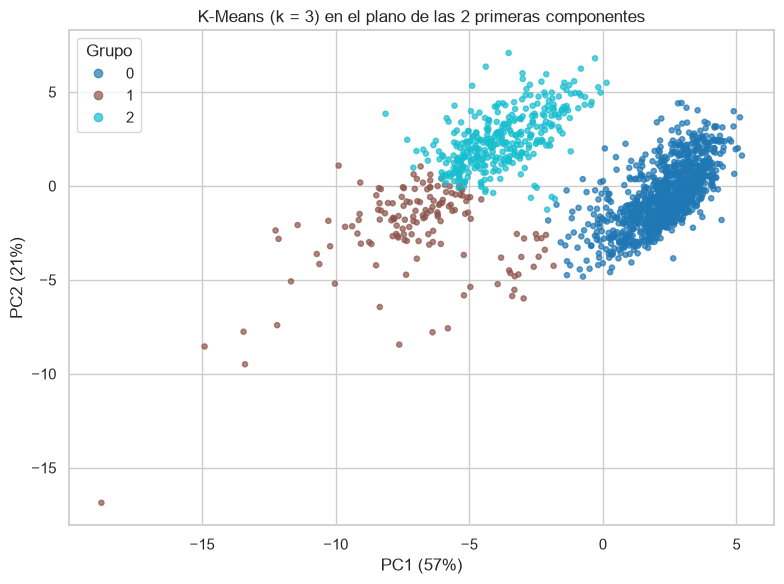

In [7]:
pca = PCA(n_components=2, random_state=config.SEMILLA)
Z = pca.fit_transform(X)
print("Varianza explicada por PC1 y PC2:", np.round(pca.explained_variance_ratio_, 3),
      "| total:", round(float(pca.explained_variance_ratio_.sum()), 3))

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(Z[:, 0], Z[:, 1], c=km.labels_, cmap="tab10", s=14, alpha=0.7)
ax.set(title=f"K-Means (k = {K}) en el plano de las 2 primeras componentes",
       xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend(*sc.legend_elements(), title="Grupo", loc="best")
guardar("nosup_pca_kmeans")
plt.show()

*Interpretación:* si PC1 y PC2 explican poca varianza, la imagen en 2D es una simplificación y dos grupos que se ven mezclados pueden estar separados en las otras dimensiones. ¿Los grupos se ven separados o se tocan? Una nube continua sin huecos indica que los tipos de día no son fronteras nítidas sino un gradiente.

## 5. Interpretar cada grupo en términos del problema
Los algoritmos no saben qué es un «laboral». Para ponerles nombre se compara cada grupo con información que el algoritmo **no usó**: día de la semana y festivo.

In [8]:
resumen = no_supervisado.describir_clusters(perfiles, km.labels_, meta)
resumen.round(2)

,n_dias,pct_fin_de_semana,pct_festivo,volumen_medio,hora_pico_manana,hora_pico_tarde,volumen_pico
grupo,,,,,,,
0,1011,0.00,0.01,3640.84,7,16,6366.87
1,149,0.62,0.21,2203.38,11,15,3815.83
2,348,0.98,0.00,2765.84,11,14,4595.12


In [31]:
nombres_auto = no_supervisado.nombrar_clusters(resumen)
print("Nombres automáticos de partida:", nombres_auto)

# Corrige aquí los nombres si, tras mirar las gráficas, algún grupo merece otro (ejemplo: {0: "Laboral", 1: "Fin de semana"})
NOMBRES_MANUALES = {
    0: "Laboral",
    2: "Sábado / fin de semana activo",
    1: "Domingo o festivo"
}
nombres = {**nombres_auto, **NOMBRES_MANUALES}
etiqueta = pd.Series(km.labels_, index=perfiles.index).map(nombres).rename("tipo_de_dia")
etiqueta.value_counts().to_frame("n_dias")

Nombres automáticos de partida: {2: 'Fin de semana o festivo A', 1: 'Fin de semana o festivo B', 0: 'Laboral'}


,n_dias
tipo_de_dia,
Laboral,1011
Sábado / fin de semana activo,348
Domingo o festivo,149


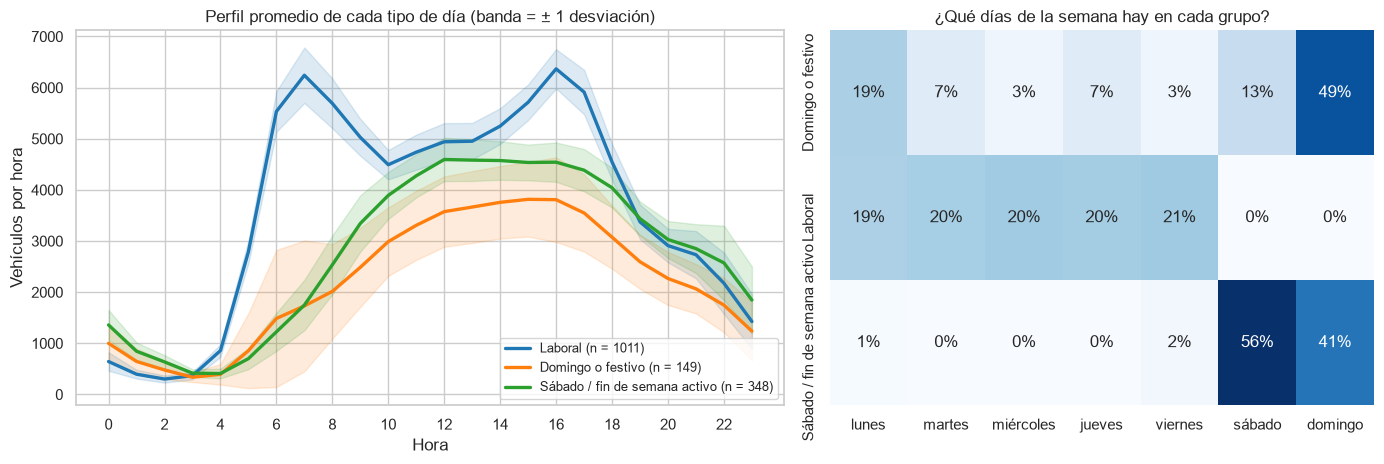

In [32]:
colores = sns.color_palette("tab10", K)
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
for g, color in zip(sorted(nombres), colores):
    dias_g = perfiles[km.labels_ == g]
    media, desv = dias_g.mean(), dias_g.std()
    ejes[0].plot(range(24), media.values, color=color, lw=2.4, label=f"{nombres[g]} (n = {len(dias_g)})")
    ejes[0].fill_between(range(24), (media - desv).values, (media + desv).values, color=color, alpha=0.15)
ejes[0].set(title="Perfil promedio de cada tipo de día (banda = ± 1 desviación)", xlabel="Hora",
            ylabel="Vehículos por hora", xticks=range(0, 24, 2))
ejes[0].legend(fontsize=9)

comp = pd.crosstab(etiqueta, meta.reindex(perfiles.index)["dia_semana"].map(dict(enumerate(no_supervisado.DIAS))),
                   normalize="index").reindex(columns=no_supervisado.DIAS)
sns.heatmap(comp, annot=True, fmt=".0%", cmap="Blues", ax=ejes[1], cbar=False)
ejes[1].set(title="¿Qué días de la semana hay en cada grupo?", xlabel="", ylabel="")
guardar("nosup_perfiles_por_tipo")
plt.show()

Con k = 3 se identifican tres patrones viales claramente diferenciados sin haberle dado al modelo el día de la semana: el grupo Laboral (n = 1011) presenta un comportamiento bimodal con picos pronunciados de entrada (7:00 h, ~6,200 veh/h) y salida (16:00 h, ~6,400 veh/h) de lunes a viernes; el grupo Sábado / fin de semana activo (n = 348) muestra una meseta sostenida de mediodía a tarde (~4,600 veh/h), agrupando el 56% de los sábados y 41% de los domingos con mayor actividad comercial; finalmente, Domingo o festivo (n = 149) registra el flujo más bajo (~3,700 veh/h) y concentra principalmente domingos tranquilos (49%) junto con lunes festivos (19%).

## 6. DBSCAN: agrupar por densidad y detectar días raros
DBSCAN necesita dos parámetros: `min_samples` (vecinos mínimos para formar un grupo) y `eps` (radio). El `eps` se elige mirando la gráfica de distancias al k-ésimo vecino: el «codo» marca el punto donde empiezan los días aislados.

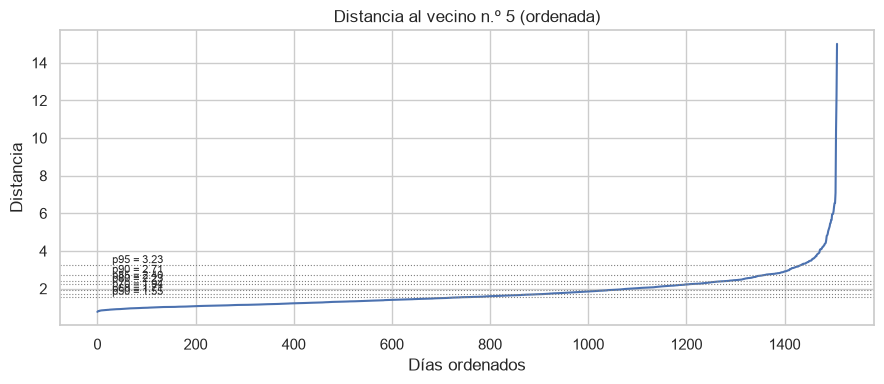

In [33]:
MIN_SAMPLES = 5
kdist = no_supervisado.distancias_kvecinos(X, MIN_SAMPLES)
percentiles = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95]
eps_candidatos = np.quantile(kdist, percentiles)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(kdist)
for p, e in zip(percentiles, eps_candidatos):
    ax.axhline(e, color="gray", ls=":", lw=0.8)
    ax.text(len(kdist) * 0.02, e, f"p{int(p*100)} = {e:.2f}", fontsize=8, va="bottom")
ax.set(title=f"Distancia al vecino n.º {MIN_SAMPLES} (ordenada)", xlabel="Días ordenados", ylabel="Distancia")
guardar("nosup_dbscan_kdist")
plt.show()

In [34]:
tabla_db = no_supervisado.evaluar_dbscan(X, eps_candidatos, MIN_SAMPLES)
tabla_db.round(3)

,eps,min_samples,n_grupos,proporcion_ruido,silueta_sin_ruido
0,1.548,5,6,0.397,0.468
1,1.707,5,3,0.298,0.491
2,1.939,5,3,0.213,0.493
3,2.233,5,3,0.123,0.314
4,2.398,5,3,0.094,0.308
5,2.711,5,1,0.056,NaN
6,3.230,5,1,0.032,NaN


*Interpretación:* a `eps` pequeño casi todo es ruido; a `eps` grande todo se junta en un solo grupo. Se busca un punto intermedio con al menos 2 grupos y poco ruido. La regla del código (mayor silueta con ≤ 15 % de ruido) es un punto de partida: cámbiala si tu criterio es otro y explícalo.

eps usado: 2.233 | grupos: 3 | ruido: 12.3% (185 días)


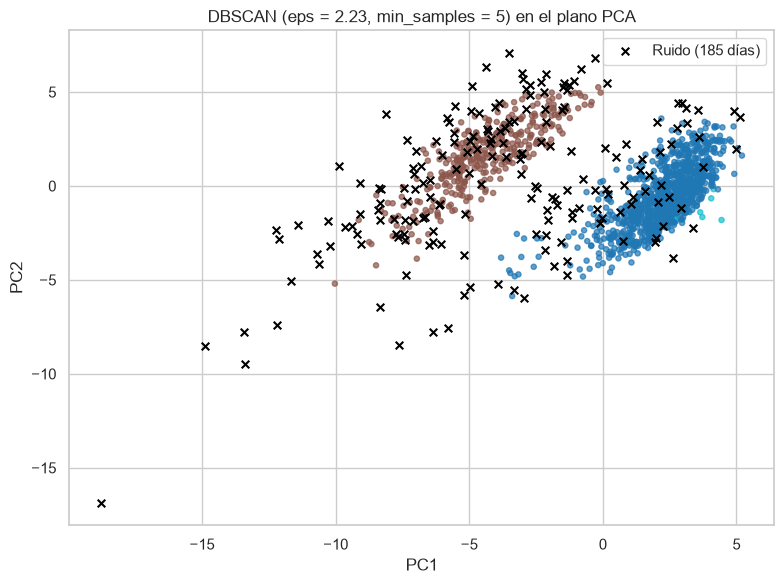

In [35]:
EPS_ELEGIDO = None      # escribe un número (por ejemplo 3.6) para forzar tu elección; None = regla automática

fila = no_supervisado.elegir_eps(tabla_db)
EPS = EPS_ELEGIDO or float(fila["eps"])
from sklearn.cluster import DBSCAN
db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(X)
et_db = db.labels_
n_g, ruido = len(set(et_db) - {-1}), (et_db == -1).mean()
print(f"eps usado: {EPS:.3f} | grupos: {n_g} | ruido: {ruido:.1%} ({(et_db == -1).sum()} días)")

fig, ax = plt.subplots(figsize=(8, 6))
m = et_db == -1
ax.scatter(Z[~m, 0], Z[~m, 1], c=et_db[~m], cmap="tab10", s=14, alpha=0.7)
ax.scatter(Z[m, 0], Z[m, 1], c="black", marker="x", s=30, label=f"Ruido ({m.sum()} días)")
ax.set(title=f"DBSCAN (eps = {EPS:.2f}, min_samples = {MIN_SAMPLES}) en el plano PCA", xlabel="PC1", ylabel="PC2")
ax.legend()
guardar("nosup_pca_dbscan")
plt.show()

In [36]:
# ¿Qué días marcó DBSCAN como ruido?
ruido_dias = meta.reindex(perfiles.index)[et_db == -1].copy()
ruido_dias["dia"] = ruido_dias["dia_semana"].map(dict(enumerate(no_supervisado.DIAS)))
ruido_dias["volumen_medio"] = perfiles[et_db == -1].mean(axis=1).round(0)
ruido_dias[["dia", "festivo", "volumen_medio"]].head(25)

,dia,festivo,volumen_medio
fecha,,,
2012-10-05,viernes,False,3964.0
2012-10-07,domingo,False,2869.0
2012-10-27,sábado,False,3065.0
2012-11-04,domingo,False,2325.0
2012-11-05,lunes,False,3586.0
2012-11-07,miércoles,False,3694.0
2012-11-11,domingo,False,2367.0
2012-11-12,lunes,True,2910.0
2012-12-09,domingo,False,1241.0


*Interpretación:* los días de ruido suelen ser **tormentas, accidentes, festivos puente o fallas de sensor**: curvas que no se parecen a ningún tipo habitual. ¿Qué tienen en común los que ves aquí (día de la semana, festivo, volumen muy bajo)? Ese es el valor propio de DBSCAN frente a K-Means, que obliga a cada día a pertenecer a algún grupo.

## 7. Comparar K-Means y DBSCAN

In [37]:
sin_ruido = et_db != -1
ari = adjusted_rand_score(km.labels_[sin_ruido], et_db[sin_ruido]) if n_g >= 1 and sin_ruido.sum() > 1 else float("nan")
from sklearn.metrics import silhouette_score
comparacion = pd.DataFrame({
    "K-Means": {"grupos": K, "ruido": 0.0, "silueta": silhouette_score(X, km.labels_)},
    "DBSCAN": {"grupos": n_g, "ruido": ruido,
               "silueta": silhouette_score(X[sin_ruido], et_db[sin_ruido]) if n_g >= 2 else float("nan")},
}).T
print(f"Acuerdo entre ambos en los días que DBSCAN agrupó (índice de Rand ajustado): {ari:.3f}  (1 = idénticos)")
comparacion.round(3)

Acuerdo entre ambos en los días que DBSCAN agrupó (índice de Rand ajustado): 0.906  (1 = idénticos)


,grupos,ruido,silueta
K-Means,3.0,0.000,0.456
DBSCAN,3.0,0.123,0.314


*Interpretación:* la silueta de DBSCAN se calcula sin los días de ruido, así que **no es directamente comparable** con la de K-Means (que clasifica todos). Comenta qué aporta cada método: K-Means da una partición completa y estable; DBSCAN da un número de grupos que descubre solo y señala los días anómalos.

## 8. Propuesta de horario de semáforo por tipo de día
Idea: cuando el tráfico es alto, el semáforo necesita un ciclo más largo (menos cambios de fase, más autos que pasan por verde); cuando es bajo, un ciclo corto evita esperas innecesarias. Se convierte el perfil de cada grupo en franjas con un ciclo sugerido.

> **Supuestos de partida:** ciclos de 45 s (bajo), 70 s (medio) y 100 s (alto), y niveles por terciles de todo el volumen horario. Son **hipótesis**, no resultados: la semana 3 las pondrá a prueba con el simulador de refuerzo.

In [38]:
cortes = no_supervisado.cortes_globales(perfiles)
print("Cortes de nivel horario: bajo <= {:.0f} < medio <= {:.0f} < alto".format(*cortes))

propuestas = {}
for g in sorted(nombres):
    perfil_g = perfiles[km.labels_ == g].mean()
    tabla_g = no_supervisado.propuesta_semaforo(perfil_g, cortes)
    propuestas[nombres[g]] = tabla_g
    print(f"\n=== {nombres[g]} ===")
    display(tabla_g)

Cortes de nivel horario: bajo <= 2308 < medio <= 4595 < alto

=== Laboral ===


,franja,nivel,volumen_medio,ciclo_sugerido_s
0,00:00 a 04:59,bajo,513,45
1,05:00 a 05:59,medio,2790,70
2,06:00 a 09:59,alto,5624,100
3,10:00 a 10:59,medio,4493,70
4,11:00 a 17:59,alto,5410,100
5,18:00 a 21:59,medio,3391,70
6,22:00 a 23:59,bajo,1800,45



=== Domingo o festivo ===


,franja,nivel,volumen_medio,ciclo_sugerido_s
0,00:00 a 08:59,bajo,994,45
1,09:00 a 19:59,medio,3329,70
2,20:00 a 23:59,bajo,1830,45



=== Sábado / fin de semana activo ===


,franja,nivel,volumen_medio,ciclo_sugerido_s
0,00:00 a 07:59,bajo,917,45
1,08:00 a 11:59,medio,3512,70
2,12:00 a 12:59,alto,4595,100
3,13:00 a 22:59,medio,3855,70
4,23:00 a 23:59,bajo,1847,45


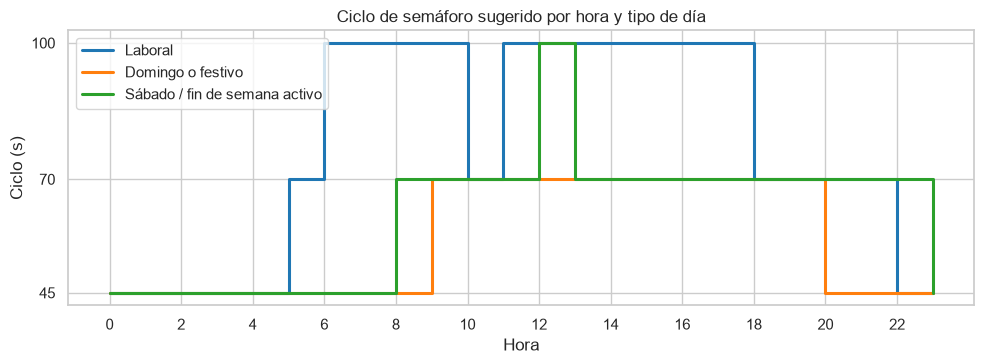

In [39]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for g, color in zip(sorted(nombres), colores):
    perfil_g = perfiles[km.labels_ == g].mean()
    ciclo = [no_supervisado.CICLO_POR_NIVEL[no_supervisado._nivel(v, cortes)] for v in perfil_g.values]
    ax.step(range(24), ciclo, where="post", color=color, lw=2.2, label=nombres[g])
ax.set(title="Ciclo de semáforo sugerido por hora y tipo de día", xlabel="Hora", ylabel="Ciclo (s)",
       xticks=range(0, 24, 2), yticks=sorted(no_supervisado.CICLO_POR_NIVEL.values()))
ax.legend()
guardar("nosup_semaforo_propuesto")
plt.show()

Interpretación: Las franjas propuestas tienen pleno sentido operativo porque mantienen bloques estables de varias horas seguidas sin cambios bruscos hora con hora, evitando desincronizar las olas verdes de los corredores viales. En la práctica, el perfil Laboral exige ciclos largos de 100 s en dos bloques amplios de alta demanda (de 6:00 a 10:00 h y de 11:00 a 18:00 h), mientras que Sábado / fin de semana activo opera casi todo el día en ciclo medio (70 s, de 8:00 a 23:00 h) con un único refuerzo de 100 s al mediodía (12:00–13:00 h), y Domingo o festivo nunca requiere ciclos de 100 s, reduciendo a 45 s desde las 20:00 h hasta las 9:00 h del día siguiente. Para validar estos tiempos en campo habría que medir demoras promedio por vehículo, longitud de colas en intersecciones críticas y tiempo total de recorrido antes y después de aplicar el calendario.

## 9. Guardar los modelos y los resultados

In [40]:
paquete_km = {"version": "semana2", "scaler": escalador, "kmeans": km, "k": K, "nombres": nombres,
              "horas": list(range(24)), "cortes_nivel": cortes,
              "propuesta_semaforo": {n: t.to_dict("records") for n, t in propuestas.items()},
              "silueta": float(silhouette_score(X, km.labels_))}
no_supervisado.guardar(paquete_km, no_supervisado.RUTA_KMEANS)

paquete_db = {"version": "semana2", "scaler": escalador, "eps": EPS, "min_samples": MIN_SAMPLES,
              "n_grupos": n_g, "proporcion_ruido": float(ruido)}
no_supervisado.guardar(paquete_db, no_supervisado.RUTA_DBSCAN)

# Tablas para el informe (pequeñas, se suben a GitHub)
reportes = config.RAIZ / "reports"
resumen.assign(tipo_de_dia=pd.Series(nombres)).round(3).to_csv(reportes / "tabla_clusters.csv")
pd.concat([t.assign(tipo_de_dia=n) for n, t in propuestas.items()]).to_csv(reportes / "propuesta_semaforo.csv", index=False)

# Etiqueta de cada día (grande, queda en data/processed y NO se sube)
config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
pd.DataFrame({"tipo_kmeans": etiqueta, "grupo_dbscan": et_db}, index=perfiles.index) \
  .to_csv(config.DATA_PROCESSED / "dias_clusters.csv")
print("Guardado en models/ y reports/")

Guardado en models/ y reports/


In [41]:
# Prueba de uso: así clasificará la app un día nuevo
paq = no_supervisado.cargar_kmeans()
for g in sorted(paq["nombres"]):
    ejemplo = perfiles[km.labels_ == g].iloc[0].values
    print(f"Día real del grupo {g}:", no_supervisado.clasificar_dia(paq, ejemplo))

Día real del grupo 0: {'grupo': 0, 'tipo_de_dia': 'Laboral'}
Día real del grupo 1: {'grupo': 1, 'tipo_de_dia': 'Domingo o festivo'}
Día real del grupo 2: {'grupo': 2, 'tipo_de_dia': 'Sábado / fin de semana activo'}


## Conclusiones del módulo no supervisado

1. **Elección de $k = 3$ grupos:** Aunque el coeficiente de silueta máximo favorece $k = 2$ (0.489)[cite: 20], se eligió **$k = 3$** (silueta = **0.455**[cite: 25]) porque mantiene una separación casi igual de sólida antes de la caída brusca en $k = 4$[cite: 25] y permite distinguir tres patrones operativos necesarios para la semaforización[cite: 20, 34].
2. **Caracterización de los tres tipos de día:** Sin utilizar la etiqueta de calendario[cite: 28], K-Means separó:
   * **Grupo 0 — Laboral (1,011 días)[cite: 32, 33, 35]:** Curva bimodal con picos marcados a las 7:00 h (~6,200 veh/h) y 16:00 h (~6,400 veh/h)[cite: 33], concentrando exclusivamente días de lunes a viernes (0% fines de semana)[cite: 33].
   * **Grupo 2 — Sábado / fin de semana activo (348 días)[cite: 32, 33, 35]:** Meseta sostenida de mediodía a tarde (~4,600 veh/h) que agrupa el 56% de los sábados y 41% de los domingos de alta movilidad[cite: 33].
   * **Grupo 1 — Domingo o festivo (149 días)[cite: 32, 33, 35]:** Flujo más bajo (~3,700 veh/h) correspondiente al 49% de domingos tranquilos y al 19% de lunes festivos[cite: 33].
3. **Detección de ruido con DBSCAN:** Con `eps = 2.233`, DBSCAN detectó 3 grupos densos y marcó como ruido el **12.3% (185 días)**[cite: 22], aislando jornadas atípicas (tormentas invernales, cierres viales o festivos especiales) que se desvían del comportamiento semanal estándar.
4. **Complementariedad de métodos:** K-Means resulta ideal para asignar cada día nuevo a un perfil operativo cerrado para el control de semáforos[cite: 34, 35], mientras que DBSCAN aporta la detección automática de anomalías sin forzar días extraordinarios dentro de los promedios habituales.
5. **Propuesta de horarios de semáforo:** Se definieron bloques estables de ciclos de **45 s, 70 s y 100 s**[cite: 34]: el perfil **Laboral** exige 100 s en dos bloques amplios (6:00–10:00 h y 11:00–18:00 h)[cite: 34]; **Sábado / fin de semana activo** opera en 70 s casi todo el día (8:00–23:00 h) con refuerzo de 100 s solo a las 12:00–13:00 h[cite: 34]; y **Domingo o festivo** nunca requiere 100 s, bajando a 45 s de 20:00 a 9:00 h[cite: 34]. Esto asume que el volumen vehicular se traduce directamente en saturación de intersecciones sin incidentes extraordinarios.
6. **Limitaciones:** El modelo analiza una sola vía (I-94)[cite: 2], descarta días con horas faltantes para mantener vectores completos de 24 dimensiones y, al aplicar `StandardScaler` por hora[cite: 19, 26], prioriza la forma de la curva sobre la magnitud absoluta del tráfico.